# Ćwiczenie 4 – wielowarstwowa sieć perceptronowa (Keras) do klasyfikacji tekstur

**Programowanie w obliczeniach inteligentnych**

Notebook klasyfikuje wektory cech tekstury (72 cechy GLCM, 3 klasy) z ćwiczenia 3 za pomocą
sieci typu MLP: `72 → 10 (sigmoid) → 3 (softmax)`.

Uruchomienie w **Google Colaboratory**: *Plik → Prześlij notatnik*, *Środowisko wykonawcze → Zmień typ środowiska wykonawczego → GPU*,
*Połącz → Połącz z hostowanym środowiskiem wykonawczym*, a plik `texture_features.csv` zostanie wczytany w komórce poniżej
(okno wyboru pliku). Lokalnie wystarczy mieć plik CSV w katalogu notebooka.

In [1]:
# Przygotowanie środowiska: informacja o dostępnych urządzeniach i wczytanie pliku z danymi (Colab)
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # mniej komunikatów TensorFlow
import warnings
warnings.filterwarnings("ignore", message="Do not pass an `input_shape`")   # ostrzeżenie Keras 3 o input_dim (instrukcja wymaga input_dim)

import tensorflow as tf
print("TensorFlow:", tf.__version__, "| urządzenia GPU:", tf.config.list_physical_devices("GPU"))

CSV_PATH = "texture_features.csv"
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files          # działa tylko w Colab
        files.upload()                           # wskaż plik texture_features.csv z ćwiczenia 3
    except ImportError:
        raise FileNotFoundError(f"Brak pliku {CSV_PATH} w katalogu roboczym {os.getcwd()}")
print("Plik z danymi:", CSV_PATH, "-", os.path.getsize(CSV_PATH), "B")

TensorFlow: 2.21.0 | urządzenia GPU: []
Plik z danymi: texture_features.csv - 270581 B


## a. Import modułów i pakietów

In [2]:
import numpy as np
from keras import Sequential
from keras.layers import Dense
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

# dodatkowe pakiety (wykresy, ziarno losowości)
import keras
import matplotlib.pyplot as plt
SEED = 42

## b. Wczytywanie danych z pliku csv

In [3]:
data = pd.read_csv(CSV_PATH)                 # funkcja read_csv z pakietu pandas
print("Kształt tabeli:", data.shape)
X = data.iloc[:, :72].values                 # wektory cech -> macierz X (192 x 72)
y = data["category"].values                  # etykiety kategorii -> wektor y
print("X:", X.shape, "| y:", y.shape, "| klasy:", np.unique(y))
print("Zakres wartości cech: min = %.3f, max = %.3f" % (X.min(), X.max()))

Kształt tabeli: (192, 73)
X: (192, 72) | y: (192,) | klasy: ['cegla' 'trawa' 'zwir']
Zakres wartości cech: min = -0.241, max = 225.908


## c. Wstępne przetwarzanie danych

In [4]:
# i. kodowanie całkowitoliczbowe etykiet: y -> y_int
label_encoder = LabelEncoder()
y_int = label_encoder.fit_transform(y)
print("Klasy (kolejność kodów 0,1,2):", list(label_encoder.classes_))

# ii. kodowanie 1 z n: y_int -> y_onehot
onehot_encoder = OneHotEncoder(sparse_output=False)
y_onehot = onehot_encoder.fit_transform(y_int.reshape(-1, 1))
print("y_onehot:", y_onehot.shape, "| przykład:", y_int[0], "->", y_onehot[0])

# iii. podział na część treningową (70%) i testową (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot, test_size=0.3, random_state=SEED)
print("Zbiór treningowy:", X_train.shape, "| testowy:", X_test.shape)

Klasy (kolejność kodów 0,1,2): ['cegla', 'trawa', 'zwir']
y_onehot: (192, 3) | przykład: 0 -> [1. 0. 0.]
Zbiór treningowy: (134, 72) | testowy: (58, 72)


## d. Tworzenie modelu sieci neuronowej

In [5]:
keras.utils.set_random_seed(SEED)                       # powtarzalność inicjalizacji wag

model = Sequential()                                     # i. obiekt sieci typu Sequential
model.add(Dense(10, input_dim=72, activation="sigmoid")) # ii. warstwa ukryta: 10 perceptronów, sigmoid
model.add(Dense(3, activation="softmax"))                #     warstwa wyjściowa: 3 neurony (klasy), softmax
model.compile(loss="categorical_crossentropy",           # iii. funkcja straty
              optimizer="sgd",                           #      stochastyczny spadek gradientu
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           730 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 763 (2.98 KB)

 Trainable params: 763 (2.98 KB)

 Non-trainable params: 0 (0.00 B)

## e. Uczenie sieci

In [6]:
history = model.fit(X_train, y_train, epochs=100, batch_size=10, shuffle=True, verbose=0)

for ep in (1, 10, 25, 50, 75, 100):
    print(f"epoka {ep:3d}:  loss = {history.history['loss'][ep-1]:.4f},  accuracy = {history.history['accuracy'][ep-1]:.4f}")

epoka   1:  loss = 1.0075,  accuracy = 0.5746
epoka  10:  loss = 0.7518,  accuracy = 0.6418
epoka  25:  loss = 0.6286,  accuracy = 0.8955
epoka  50:  loss = 0.6104,  accuracy = 0.6567
epoka  75:  loss = 0.5733,  accuracy = 0.6493
epoka 100:  loss = 0.5500,  accuracy = 0.6418


## f. Testowanie sieci

In [7]:
y_pred = model.predict(X_test, verbose=0)
y_pred_int = np.argmax(y_pred, axis=1)       # i. kodowanie całkowite: z wektorów prawdopodobieństw / one-hot
y_test_int = np.argmax(y_test, axis=1)
cm = confusion_matrix(y_test_int, y_pred_int)   # ii. macierz pomyłek
print(cm)
acc_base = float(np.mean(y_pred_int == y_test_int))
print("Dokładność na zbiorze testowym: %.4f (%d/%d)" % (acc_base, np.sum(y_pred_int == y_test_int), len(y_test_int)))

[[18  0  0]
 [ 0  0 20]
 [ 1  0 19]]
Dokładność na zbiorze testowym: 0.6379 (37/58)


## g. Rozszerzenie (poza instrukcją): standaryzacja cech

Cechy GLCM mają bardzo różne skale (np. *contrast* sięga ~226, a *energy* jest rzędu 0,01), a w sieci z funkcją sigmoid
trenowanej metodą SGD duże wartości wejściowe nasycają neurony i spowalniają uczenie. Poniżej ta sama sieć, ale z cechami
standaryzowanymi (średnia 0, odchylenie 1; parametry wyznaczone **tylko** na zbiorze treningowym).

In [8]:
from sklearn.preprocessing import StandardScaler

def build_model(seed):
    keras.utils.set_random_seed(seed)
    m = Sequential()
    m.add(Dense(10, input_dim=72, activation="sigmoid"))
    m.add(Dense(3, activation="softmax"))
    m.compile(loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])
    return m

scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

model_s = build_model(SEED)
history_s = model_s.fit(Xs_train, y_train, epochs=100, batch_size=10, shuffle=True, verbose=0)
y_pred_s = np.argmax(model_s.predict(Xs_test, verbose=0), axis=1)
cm_s = confusion_matrix(y_test_int, y_pred_s)
acc_std = float(np.mean(y_pred_s == y_test_int))
print(cm_s)
print("Dokładność na zbiorze testowym po standaryzacji: %.4f (%d/%d)" % (acc_std, np.sum(y_pred_s == y_test_int), len(y_test_int)))
print("Końcowa strata uczenia: bez standaryzacji = %.4f, ze standaryzacją = %.4f" % (history.history['loss'][-1], history_s.history['loss'][-1]))

[[18  0  0]
 [ 0 17  3]
 [ 0  0 20]]
Dokładność na zbiorze testowym po standaryzacji: 0.9483 (55/58)
Końcowa strata uczenia: bez standaryzacji = 0.5500, ze standaryzacją = 0.1408


## h. Powtarzalność wyniku (5 różnych inicjalizacji wag)

Wynik pojedynczego uczenia zależy od losowej inicjalizacji wag. Dla porównania obu wariantów powtarzamy uczenie dla pięciu ziaren.

In [9]:
seeds = [42, 1, 2, 3, 4]
raw_accs, std_accs = [], []
for s in seeds:
    m = build_model(s); m.fit(X_train, y_train, epochs=100, batch_size=10, shuffle=True, verbose=0)
    raw_accs.append(float(np.mean(np.argmax(m.predict(X_test, verbose=0), 1) == y_test_int)))
    m = build_model(s); m.fit(Xs_train, y_train, epochs=100, batch_size=10, shuffle=True, verbose=0)
    std_accs.append(float(np.mean(np.argmax(m.predict(Xs_test, verbose=0), 1) == y_test_int)))
results_table = pd.DataFrame({"ziarno": seeds, "bez standaryzacji": raw_accs, "ze standaryzacją": std_accs})
print(results_table.to_string(index=False))
print("średnia ± odch. std.: bez standaryzacji %.3f ± %.3f | ze standaryzacją %.3f ± %.3f" %
      (np.mean(raw_accs), np.std(raw_accs), np.mean(std_accs), np.std(std_accs)))

 ziarno  bez standaryzacji  ze standaryzacją
     42           0.637931          0.948276
      1           0.948276          0.948276
      2           0.637931          0.948276
      3           0.620690          0.948276
      4           0.655172          0.948276
średnia ± odch. std.: bez standaryzacji 0.700 ± 0.125 | ze standaryzacją 0.948 ± 0.000


## i. Wykresy i zapis wyników (do sprawozdania)

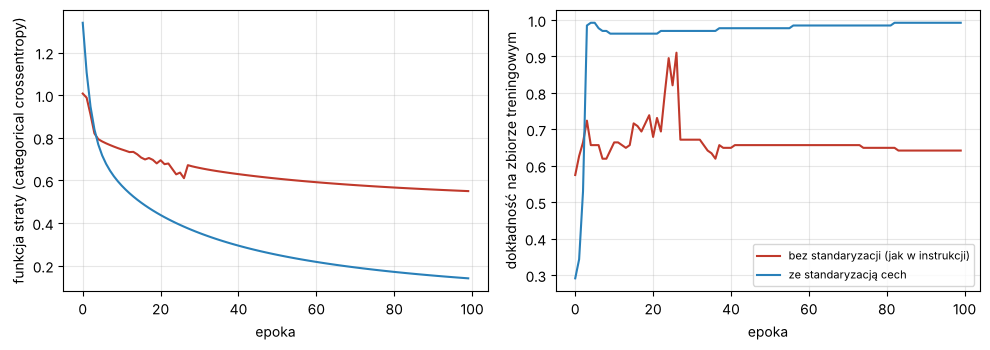

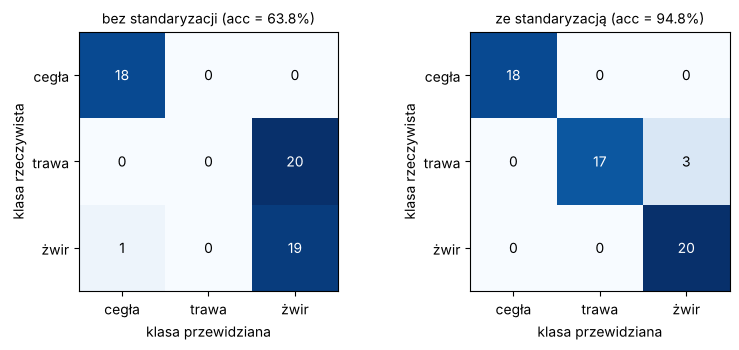

Zapisano figures/lab4_*.png oraz results/lab4_results.json


In [10]:
import json, os
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
names = {"cegla": "cegła", "trawa": "trawa", "zwir": "żwir"}
labels = [names[c] for c in label_encoder.classes_]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for h, lab, col in [(history, "bez standaryzacji (jak w instrukcji)", "#c0392b"), (history_s, "ze standaryzacją cech", "#2980b9")]:
    ax[0].plot(h.history["loss"], label=lab, color=col)
    ax[1].plot(h.history["accuracy"], label=lab, color=col)
ax[0].set_xlabel("epoka"); ax[0].set_ylabel("funkcja straty (categorical crossentropy)"); ax[0].grid(alpha=.3)
ax[1].set_xlabel("epoka"); ax[1].set_ylabel("dokładność na zbiorze treningowym"); ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/lab4_training_curves.png", dpi=170); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
for a, c_, t in [(ax[0], cm, f"bez standaryzacji (acc = {acc_base:.1%})"), (ax[1], cm_s, f"ze standaryzacją (acc = {acc_std:.1%})")]:
    a.imshow(c_, cmap="Blues"); a.set_title(t, fontsize=10)
    a.set_xticks(range(3)); a.set_yticks(range(3)); a.set_xticklabels(labels); a.set_yticklabels(labels)
    a.set_xlabel("klasa przewidziana"); a.set_ylabel("klasa rzeczywista")
    for i in range(3):
        for j in range(3):
            a.text(j, i, int(c_[i, j]), ha="center", va="center", color="white" if c_[i, j] > c_.max() / 2 else "black")
fig.tight_layout(); fig.savefig("figures/lab4_confusion.png", dpi=170); plt.show()

json.dump(dict(
    keras=keras.__version__, backend=keras.backend.backend(), tensorflow=tf.__version__,
    gpu=[str(d) for d in tf.config.list_physical_devices("GPU")], seed=SEED,
    n_train=int(len(X_train)), n_test=int(len(X_test)), classes=list(label_encoder.classes_),
    n_params=int(model.count_params()),
    baseline=dict(final_loss=float(history.history["loss"][-1]), final_train_acc=float(history.history["accuracy"][-1]),
                  test_acc=acc_base, confusion_matrix=cm.tolist(),
                  loss_curve=[float(v) for v in history.history["loss"]], acc_curve=[float(v) for v in history.history["accuracy"]]),
    standardized=dict(final_loss=float(history_s.history["loss"][-1]), final_train_acc=float(history_s.history["accuracy"][-1]),
                      test_acc=acc_std, confusion_matrix=cm_s.tolist(),
                      loss_curve=[float(v) for v in history_s.history["loss"]], acc_curve=[float(v) for v in history_s.history["accuracy"]]),
    seeds=dict(seeds=seeds, raw=raw_accs, standardized=std_accs,
               raw_mean=float(np.mean(raw_accs)), raw_std=float(np.std(raw_accs)),
               std_mean=float(np.mean(std_accs)), std_std=float(np.std(std_accs))),
), open("results/lab4_results.json", "w"), indent=2, ensure_ascii=False)
print("Zapisano figures/lab4_*.png oraz results/lab4_results.json")